# 03 – Entraînement et évaluation du modèle (Spark MLlib)

**Question :** combien de fraudes le modèle détecte-t-il sur des jours qu'il n'a jamais vus, et grâce à quoi ?

Ce notebook refait **pas à pas** ce que fait `python -m src.ml.train_model` (mêmes fonctions, importées de `src/ml/`),
puis présente les résultats complets enregistrés dans `models/metrics*.json` par :
```bash
python -m src.ml.train_model --compare --test-data data/transactions_test.csv                    # modèle retenu
python -m src.ml.train_model --algo rf --sans-profils   --test-data data/transactions_test.csv   # expériences
python -m src.ml.train_model --algo rf --sans-frequence --test-data data/transactions_test.csv
python -m src.ml.train_model --algo rf --sans-profils --sans-frequence --test-data data/transactions_test.csv
```

In [1]:
# Préparation : on travaille depuis la racine du projet pour importer src/ et config/
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E3E7EF", "axes.axisbelow": True})
AMBRE, ROUGE, TURQUOISE, GRIS = "#E89A00", "#E5384A", "#1BA597", "#C9D2E3"

In [2]:
import json
from pyspark.sql import functions as F
from config.settings import DATASET_PATH, DATA_DIR, MODEL_PATH
from src.ml.features import TX_SCHEMA, add_features, add_velocity_features, build_profiles, NUMERIC_COLS, CATEGORICAL_COLS
from src.ml.spark import get_spark
from src.ml.train_model import auc_pr, build_pipeline, with_class_weight

spark = get_spark("notebook-entrainement", conf={"spark.driver.memory": "6g", "spark.ui.showConsoleProgress": "false"})

## 1. Découpage temporel
On apprend sur le passé, on évalue sur le futur :
- **0 à 50 %** du mois : historique, uniquement pour calculer les profils de comptes ;
- **50 à 100 %** : entraînement ;
- **test** : les 7 jours suivants (`transactions_test.csv`), avec des profils calculés sur tout le mois.

In [3]:
raw = spark.read.csv(str(DATASET_PATH), header=True, schema=TX_SCHEMA).withColumn("ts_epoch", F.to_timestamp("timestamp").cast("long"))
df = add_velocity_features(raw).cache()
q50 = df.approxQuantile("ts_epoch", [0.5], 0.001)[0]
historique, entrainement = df.filter(F.col("ts_epoch") <= q50), df.filter(F.col("ts_epoch") > q50)

test_seul = spark.read.csv(str(DATA_DIR / "transactions_test.csv"), header=True, schema=TX_SCHEMA).withColumn("ts_epoch", F.to_timestamp("timestamp").cast("long"))
debut_test = test_seul.agg(F.min("ts_epoch")).first()[0]
# la dernière heure du mois sert d'historique aux fenêtres des premières transactions de test
queue = raw.filter(F.col("ts_epoch") >= debut_test - 3600).withColumn("_test", F.lit(False))
test = add_velocity_features(queue.unionByName(test_seul.withColumn("_test", F.lit(True)))).filter("_test").drop("_test")

for nom, d in (("historique (profils)", historique), ("entraînement", entrainement), ("test", test)):
    n, f = d.count(), d.filter("is_fraud = 1").count()
    print(f"{nom:22s} {n:>7,} transactions, {f:>5,} fraudes ({f / n:.2%})".replace(",", " "))

historique (profils)   101 403 transactions  1 890 fraudes (1.86%)


entraînement           101 738 transactions  2 144 fraudes (2.11%)


test                    46 566 transactions    142 fraudes (0.30%)


## 2. Profils de comptes, features et pondération des classes

In [4]:
profils_train, profils_test = build_profiles(historique).cache(), build_profiles(df).cache()
train, n, n_fraude = with_class_weight(add_features(entrainement, profils_train))
print(f"{profils_train.count():,} profils (entraînement), {profils_test.count():,} profils (test)".replace(",", " "))
print(f"Poids d'une fraude : {(n - n_fraude) / n_fraude:.0f} (une fraude compte autant que ~{(n - n_fraude) / n_fraude:.0f} transactions normales)")
print(f"{len(NUMERIC_COLS)} features numériques + {len(CATEGORICAL_COLS)} catégorielles encodées :")
print(", ".join(NUMERIC_COLS))

16 042 profils (entraînement)  16 627 profils (test)
Poids d'une fraude : 46 (une fraude compte autant que ~46 transactions normales)
20 features numériques + 3 catégorielles encodées :
amount, log_amount, sender_balance_before, hour, is_night, amount_to_balance_ratio, sender_emptied, error_balance_sender, error_balance_receiver, has_history, log_n_tx_hist, amount_vs_avg, amount_vs_max, device_is_new, receiver_is_new, city_is_new, sender_n_10min, log_sender_amount_10min, sender_n_1h, pair_n_10min


## 3. Entraînement de la forêt aléatoire (Spark MLlib) et évaluation sur le test

In [5]:
import time
t0 = time.time()
modele = build_pipeline("rf").fit(train)
pred = modele.transform(add_features(test, profils_test))
print(f"Entraînement + prédiction : {time.time() - t0:.0f} s")
print(f"AUC-PR sur le test : {auc_pr(pred):.3f}  (hasard = taux de fraude du test = {test.filter('is_fraud = 1').count() / test.count():.3f})")

Entraînement + prédiction : 232 s


AUC-PR sur le test : 0.801  (hasard = taux de fraude du test = 0.003)


Le chiffre peut varier de quelques centièmes d'un entraînement à l'autre (ordre de lecture des partitions par Spark).
Les résultats ci-dessous sont ceux du modèle **réellement déployé** (`models/metrics.json`).

## 4. Ce qui fait la différence : profils et fréquence

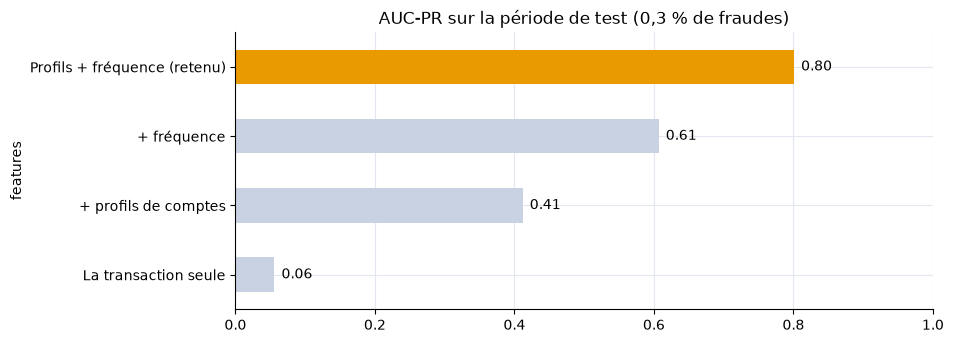

,AUC-PR,"précision (seuil 0,80)","rappel (seuil 0,80)","alertes / 1000 tx (seuil 0,50)"
features,,,,
La transaction seule,0.056,4%,42%,116
+ profils de comptes,0.412,28%,55%,50
+ fréquence,0.607,16%,73%,73
Profils + fréquence (retenu),0.801,45%,80%,18


In [6]:
variantes = {"La transaction seule": "metrics_sans_profils_sans_frequence", "+ profils de comptes": "metrics_sans_frequence",
             "+ fréquence": "metrics_sans_profils", "Profils + fréquence (retenu)": "metrics"}
lignes = []
for nom, f in variantes.items():
    m = json.load(open(f"models/{f}.json"))
    lignes.append({"features": nom, "AUC-PR": round(m["auc_pr"], 3),
                   "précision (seuil 0,80)": f"{m['at_high']['precision']:.0%}", "rappel (seuil 0,80)": f"{m['at_high']['recall']:.0%}",
                   "alertes / 1000 tx (seuil 0,50)": round(m["at_medium"]["alerts_per_1000"])})
abl = pd.DataFrame(lignes).set_index("features")
ax = abl["AUC-PR"].plot.barh(color=[GRIS, GRIS, GRIS, AMBRE], title="AUC-PR sur la période de test (0,3 % de fraudes)")
for i, v in enumerate(abl["AUC-PR"]): ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 1); plt.show()
abl

## 5. Choix de l'algorithme (validation, jamais le test)

In [7]:
m = json.load(open("models/metrics.json"))
pd.DataFrame(m["comparison"])[["label", "auc_pr_validation"]].rename(columns={"label": "algorithme", "auc_pr_validation": "AUC-PR validation"}).round(3)

,algorithme,AUC-PR validation
0,Régression logistique,0.774
1,Forêt aléatoire,0.893
2,Gradient boosting (GBT),0.887


## 6. Précision, rappel et seuils d'alerte

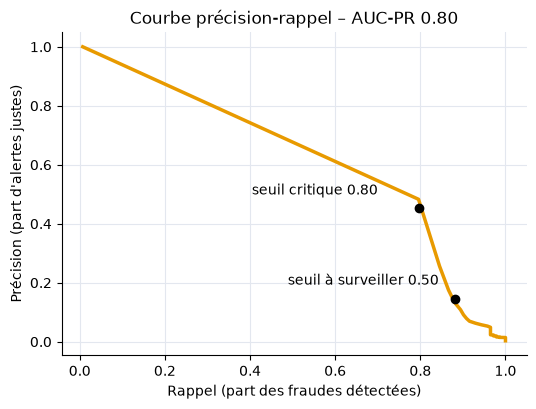

,threshold,tp,fp,fn,precision,recall,alerts_per_1000
à surveiller,0.5,125,730,17,0.146,0.880,18.361
critique,0.8,113,137,29,0.452,0.796,5.369


In [8]:
pr = pd.DataFrame(m["pr_curve"])
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(pr["recall"], pr["precision"], color=AMBRE, lw=2.5)
for cle, nom in (("at_high", "critique"), ("at_medium", "à surveiller")):
    s = m[cle]; ax.scatter(s["recall"], s["precision"], color="black", zorder=3)
    ax.annotate(f"seuil {nom} {s['threshold']:.2f}", (s["recall"], s["precision"]), xytext=(-120, 10), textcoords="offset points")
ax.set_xlabel("Rappel (part des fraudes détectées)"); ax.set_ylabel("Précision (part d'alertes justes)")
ax.set_title(f"Courbe précision-rappel – AUC-PR {m['auc_pr']:.2f}"); plt.show()
pd.DataFrame([{k: m[c][k] for k in ("threshold", "tp", "fp", "fn", "precision", "recall", "alerts_per_1000")} for c in ("at_medium", "at_high")],
             index=["à surveiller", "critique"]).round(3)

## 7. Détection par scénario et importance des features

In [9]:
noms = {"ATO": "Prise de contrôle", "VELOCITY": "Rafale", "SCAM": "Arnaque", "STRUCTURING": "Structuration", "AGENT_SPLIT": "Fractionnement agent"}
sc = pd.DataFrame(m["by_scenario"]).T.rename(index=noms)
sc[["recall_medium", "recall_high"]] = sc[["recall_medium", "recall_high"]].astype(float).round(2)
print("Attention : peu de fraudes par scénario dans le test (colonne n), ces taux sont approximatifs.")
sc[["n", "recall_medium", "recall_high"]].rename(columns={"recall_medium": "rappel seuil 0,50", "recall_high": "rappel seuil 0,80"})

Attention : peu de fraudes par scénario dans le test (colonne n), ces taux sont approximatifs.


,n,"rappel seuil 0,50","rappel seuil 0,80"
Fractionnement agent,37.0,0.89,0.89
Prise de contrôle,28.0,0.96,0.82
Arnaque,34.0,0.68,0.47
Structuration,11.0,0.91,0.91
Rafale,32.0,1.00,0.97


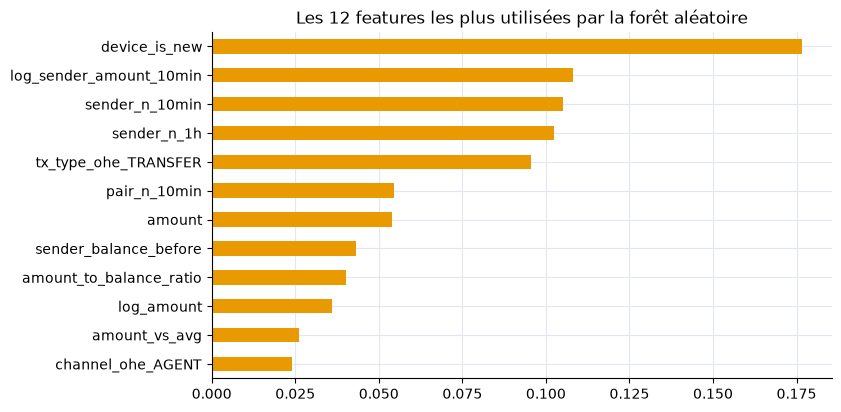

In [10]:
imp = pd.DataFrame(m["feature_importances"]).head(12).iloc[::-1]
ax = imp.plot.barh(x="feature", y="importance", color=AMBRE, legend=False, figsize=(8, 4.5),
                   title="Les 12 features les plus utilisées par la forêt aléatoire")
ax.set_ylabel(""); plt.show()

## Ce qu'il faut retenir
- Sur une période **jamais vue** à 0,3 % de fraudes, le modèle obtient une **AUC-PR d'environ 0,80** (le hasard ferait 0,003).
- La transaction seule ne suffit pas (≈ 0,06). Les **profils de comptes** (habitudes) et la **fréquence** (activité récente) sont complémentaires : ensemble, ils divisent le nombre d'alertes par 6 tout en détectant plus de fraudes.
- L'**arnaque** reste le scénario le plus difficile : la victime agit elle-même, depuis son appareil, dans sa ville.

In [11]:
spark.stop()